
1. Edit the three input blocks.
2. Run all cells.
3. Enable optional views only when needed.

****

Power: W · Time: h · Energy: Wh · Area: m²

In [10]:
# %pip install numpy pandas matplotlib ipywidgets

In [11]:
from copy import deepcopy
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

## 1. Inputs

Edit **Parameters**, **Loads**, and **Safe mode**. Use **View options** to show extra detail.

In [12]:
# PARAMETERS
mission = {
    "lifetime_years": 5.0,
    "days_per_year": 365.0,          # For the approximate cycle count
    "eclipse_h": 1.0,               # Update when orbit is confirmed
    "sunlight_h": 1.0,              # Assumed; must be > 0 for solar sizing
    "load_margin": 0.30,
}
solar_array = {
    "solar_irradiance_W_m2": 1361.0,
    "cell_efficiency": 0.30,
    "X_e": 0.60,
    "X_d": 0.80,
    "inherent_factor": 0.72,
    "annual_degradation": 0.005,
    "incidence_deg": 0.0,
}
battery = {
    "battery_to_load_efficiency": 0.90,
    "depth_of_discharge": 0.30,
    "battery_units": 1,             # N equal units sharing the required energy
    "battery_capacity_retention": None,  # EOL/temperature usable capacity / BOL nameplate
}
parameters = {**mission, **solar_array, **battery}

# LOADS                  active_W idle_W peak_W duty_e duty_d enabled
load_rows = [
    ("payload",    "Payload",                  5.6, 0.0, 5.6,  1.0, 1.0, True),
    ("mechanisms", "Structure and Mechanisms", 0.0, 0.0, 0.0,  0.0, 0.0, True),
    ("thermal",    "Thermal control",         15.0, 0.0, 15.0, 1.0, 0.0, True),
    ("eps",        "EPS electronics",          2.0, 0.0, 2.0,  1.0, 1.0, True),
    ("dsn",        "Communication DSN",       35.0, 0.0, 35.0, 0.1, 0.1, True),
    ("crosslink",  "Communication node-node", 11.0, 1.2, 11.0, 0.1, 0.1, True),
    ("broadcast",  "One-way surface broadcast",11.0,0.0,11.0, 1.0, 1.0, True),
    ("obc",        "OBC",                      2.0, 0.0, 4.0,  1.0, 1.0, True),
    ("adcs",       "ADCS",                     4.27,0.0, 8.12, 1.0, 1.0, True),
]
loads = pd.DataFrame(load_rows, columns=["id", "Subsystem", "active_W", "idle_W",
                                       "peak_W", "duty_e", "duty_d", "enabled"]).set_index("id")

# SAFE MODE: only list values that differ from nominal
safe_overrides = {
    "payload": {"enabled": False},
    "crosslink": {"enabled": False},
    "broadcast": {"enabled": False},
}

# VIEW OPTIONS
view = {
    "detailed_results": False,
    "load_chart": False,
    "scenario_output": True,
    "sweep_output": True,
}

baseline = {"parameters": deepcopy(parameters),
            "loads": loads.to_dict(orient="index"),
            "safe_overrides": deepcopy(safe_overrides)}
display(Markdown("**Loads**"), loads)
display(Markdown("**Parameters**"), pd.Series(parameters, name="Value", dtype=object).to_frame().fillna("TBD"))

**Loads**

,Subsystem,active_W,idle_W,peak_W,duty_e,duty_d,enabled
id,,,,,,,
payload,Payload,5.60,0.0,5.60,1.0,1.0,True
mechanisms,Structure and Mechanisms,0.00,0.0,0.00,0.0,0.0,True
thermal,Thermal control,15.00,0.0,15.00,1.0,0.0,True
eps,EPS electronics,2.00,0.0,2.00,1.0,1.0,True
dsn,Communication DSN,35.00,0.0,35.00,0.1,0.1,True
crosslink,Communication node-node,11.00,1.2,11.00,0.1,0.1,True
broadcast,One-way surface broadcast,11.00,0.0,11.00,1.0,1.0,True
obc,OBC,2.00,0.0,4.00,1.0,1.0,True
adcs,ADCS,4.27,0.0,8.12,1.0,1.0,True


**Parameters**

,Value
lifetime_years,5.0
days_per_year,365.0
eclipse_h,1.0
sunlight_h,1.0
load_margin,0.3
solar_irradiance_W_m2,1361.0
cell_efficiency,0.3
X_e,0.6
X_d,0.8
inherent_factor,0.72


## 2. Calculation model
Set capacity retention to include BOL sizing. `battery_units` splits capacity between units.


In [13]:
def validate_case(case):
    """Reject invalid inputs before calculating; no silent clipping."""
    p = case["parameters"]
    for key, value in p.items():
        if value is None and key == "battery_capacity_retention":
            continue
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, float, np.number)) or not math.isfinite(value):
            raise ValueError(f"{key}: enter a finite number (retention may be None).")
    for key in ["lifetime_years", "eclipse_h", "load_margin"]:
        if p[key] < 0:
            raise ValueError(f"{key} must be >= 0.")
    for key in ["sunlight_h", "days_per_year", "solar_irradiance_W_m2"]:
        if p[key] <= 0:
            raise ValueError(f"{key} must be > 0.")
    for key in ["cell_efficiency", "X_e", "X_d", "inherent_factor",
                "battery_to_load_efficiency", "depth_of_discharge", "battery_capacity_retention"]:
        if p[key] is not None and not 0 < p[key] <= 1:
            raise ValueError(f"{key} must be in (0, 1].")
    if not 0 <= p["annual_degradation"] < 1:
        raise ValueError("annual_degradation must be in [0, 1).")
    if not 0 <= p["incidence_deg"] < 90:
        raise ValueError("incidence_deg must be in [0, 90); 90 degrees has no solar output.")
    if p["battery_units"] < 1 or int(p["battery_units"]) != p["battery_units"]:
        raise ValueError("battery_units must be a positive integer.")
    for key, override in case["safe_overrides"].items():
        if key not in case["loads"]:
            raise ValueError(f"Unknown safe-mode subsystem: {key}")
        if set(override) - set(case["loads"][key]):
            raise ValueError(f"Unknown safe-mode field for {key}.")
    for mode in ["nominal", "safe"]:
        for key, row in mode_loads(case, mode).items():
            if not isinstance(row["enabled"], (bool, np.bool_)):
                raise ValueError(f"{mode}.{key}.enabled must be True or False.")
            for field in ["active_W", "idle_W", "peak_W", "duty_e", "duty_d"]:
                v = row[field]
                if isinstance(v, (bool, np.bool_)) or not isinstance(v, (int, float, np.number)) or not math.isfinite(v) or v < 0:
                    raise ValueError(f"{mode}.{key}.{field} must be a finite non-negative number.")
            if max(row["duty_e"], row["duty_d"]) > 1:
                raise ValueError(f"{mode}.{key}: duty cycles must be in [0, 1].")
            if row["peak_W"] < max(row["active_W"], row["idle_W"]):
                raise ValueError(f"{mode}.{key}: peak_W must cover active_W and idle_W.")


def mode_loads(case, mode):
    rows = deepcopy(case["loads"])
    if mode == "safe":
        for key, override in case["safe_overrides"].items():
            rows[key].update(override)
    elif mode != "nominal":
        raise ValueError("mode must be 'nominal' or 'safe'.")
    return rows


def calculate(case, mode="nominal"):
    """Return a subsystem table and scalar results; never modify the inputs."""
    validate_case(case)
    p = case["parameters"]
    te, td = p["eclipse_h"], p["sunlight_h"]
    table = pd.DataFrame.from_dict(mode_loads(case, mode), orient="index")
    on = table["enabled"].astype(float)
    table["Eclipse [W]"] = on * (table.duty_e * table.active_W + (1-table.duty_e) * table.idle_W)
    table["Sunlight [W]"] = on * (table.duty_d * table.active_W + (1-table.duty_d) * table.idle_W)
    table["Orbit average [W]"] = (table["Eclipse [W]"] * te + table["Sunlight [W]"] * td) / (te+td)
    table["Peak [W]"] = on * table.peak_W
    pe, pd_, avg, peak = table[["Eclipse [W]", "Sunlight [W]", "Orbit average [W]", "Peak [W]"]].sum()
    factor = 1 + p["load_margin"]
    pe_req, pd_req, avg_req, peak_req = factor * np.array([pe, pd_, avg, peak])
    psa = (pe_req * te / p["X_e"] + pd_req * td / p["X_d"]) / td
    p0 = p["solar_irradiance_W_m2"] * p["cell_efficiency"]
    pbol = p0 * p["inherent_factor"] * math.cos(math.radians(p["incidence_deg"]))
    ld = (1 - p["annual_degradation"]) ** p["lifetime_years"]
    peol = pbol * ld
    eclipse_energy = pe_req * te
    capacity_bank = eclipse_energy / (p["depth_of_discharge"] * p["battery_to_load_efficiency"])
    retention = p["battery_capacity_retention"]
    results = {
        "Eclipse fraction [-]": te / (te+td),
        "Orbit period [h]": te+td,
        "Approximate cycles [-]": p["lifetime_years"] * p["days_per_year"] * 24 / (te+td) if te > 0 else 0,
        "Eclipse load [W]": pe, "Sunlight load [W]": pd_,
        "Orbit average [W]": avg, "Simultaneous peak [W]": peak,
        "Eclipse load + margin [W]": pe_req, "Sunlight load + margin [W]": pd_req,
        "Orbit average + margin [W]": avg_req, "Peak + margin [W]": peak_req,
        "Array power required at EOL [W]": psa,
        "Ideal cell output [W/m2]": p0, "BOL output [W/m2]": pbol,
        "Lifetime factor [-]": ld, "EOL output [W/m2]": peol,
        "Array area [m2]": psa / peol,
        "Eclipse energy to loads [Wh]": eclipse_energy,
        "Battery bank EOL [Wh]": capacity_bank,
        "Battery per unit EOL [Wh]": capacity_bank / p["battery_units"],
        "Battery bank BOL [Wh]": np.nan if retention is None else capacity_bank / retention,
        "Battery peak at terminals [W]": peak_req / p["battery_to_load_efficiency"],
    }
    return table, pd.Series(results, dtype=float)


def changed_case(case, changes):
    """Copy a case and apply dotted input paths; baseline stays unchanged.

    Examples: parameters.eclipse_h, loads.dsn.duty_e,
    safe_overrides.dsn.duty_e. Safe overrides can be added here.
    """
    new = deepcopy(case)
    for path, value in changes.items():
        parts = path.split(".")
        if len(parts) == 2 and parts[0] == "parameters" and parts[1] in new["parameters"]:
            new["parameters"][parts[1]] = value
        elif (len(parts) == 3 and parts[0] in ["loads", "safe_overrides"]
              and parts[1] in new["loads"] and parts[2] in new["loads"][parts[1]]):
            new[parts[0]].setdefault(parts[1], {})[parts[2]] = value
        else:
            raise KeyError(f"Unknown input path: {path}")
    validate_case(new)
    return new


def show_results(case):
    outputs = {}
    for mode in ["nominal", "safe"]:
        table, outputs[mode] = calculate(case, mode)
        if view["detailed_results"]:
            display(Markdown(f"**{mode.capitalize()} loads**"))
            display(table.set_index("Subsystem")[["Eclipse [W]", "Sunlight [W]",
                                                 "Orbit average [W]", "Peak [W]"]].round(2))
    key_results = ["Orbit average + margin [W]", "Peak + margin [W]",
                   "Array power required at EOL [W]", "Array area [m2]",
                   "Battery bank EOL [Wh]", "Battery bank BOL [Wh]"]
    display(Markdown("**Key sizing results**"))
    display(pd.DataFrame(outputs).loc[key_results].round(3).fillna("TBD"))
    if view["detailed_results"]:
        display(Markdown("**All calculated results**"))
        display(pd.DataFrame(outputs).round(3).fillna("TBD"))
    return outputs

## 3. Baseline results

Review the nominal and safe-mode results.

In [14]:
baseline_results = show_results(baseline)

**Key sizing results**

,nominal,safe
Orbit average + margin [W],49.465,25.051
Peak + margin [W],119.236,83.356
Array power required at EOL [W],148.335,77.128
Array area [m2],0.517,0.269
Battery bank EOL [Wh],219.315,128.893
Battery bank BOL [Wh],TBD,TBD


In [15]:
if view["load_chart"]:
    table, _ = calculate(baseline)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    table.set_index("Subsystem")[["Eclipse [W]", "Sunlight [W]"]].plot.barh(ax=ax, color=["#355C7D", "#D49A29"])
    ax.set_xlabel("Average load power before contingency [W]")
    ax.set_ylabel("")
    ax.set_title("Nominal subsystem loads")
    ax.invert_yaxis()
    fig.tight_layout()
    plt.show()

## 4. Compare scenarios

Edit or add cases. Each case starts from the baseline.

,Orbit average + margin [W],Peak + margin [W],Array power required at EOL [W],Array area [m2],Battery bank EOL [Wh],Battery bank BOL [Wh]
Baseline,49.465,119.236,148.335,0.517,219.315,TBD
No load contingency,38.050,91.720,114.104,0.398,168.704,TBD
1.5 h eclipse / 0.5 h Sun,54.340,119.236,345.719,1.206,328.972,TBD
30 deg array incidence,49.465,119.236,148.335,0.597,219.315,TBD
20% battery DOD,49.465,119.236,148.335,0.517,328.972,TBD
Contacts only in eclipse,49.465,119.236,150.762,0.526,240.885,TBD
Broadcast disabled,35.165,104.936,106.627,0.372,166.352,TBD


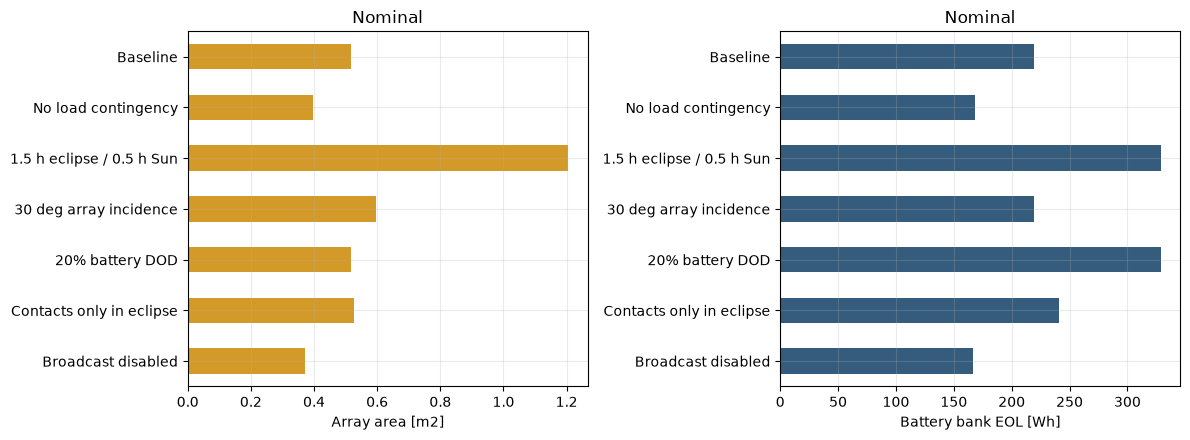

In [16]:
scenario_changes = {
    "Baseline": {},
    "No load contingency": {"parameters.load_margin": 0.0},
    "1.5 h eclipse / 0.5 h Sun": {"parameters.eclipse_h": 1.5, "parameters.sunlight_h": 0.5},
    "30 deg array incidence": {"parameters.incidence_deg": 30.0},
    "20% battery DOD": {"parameters.depth_of_discharge": 0.20},
    # Same orbit-average communication duty as baseline for equal phase durations:
    "Contacts only in eclipse": {"loads.dsn.duty_e": 0.20, "loads.dsn.duty_d": 0.0,
                                 "loads.crosslink.duty_e": 0.20, "loads.crosslink.duty_d": 0.0},
    "Broadcast disabled": {"loads.broadcast.enabled": False},
}

comparison_columns = ["Orbit average + margin [W]", "Peak + margin [W]",
                      "Array power required at EOL [W]", "Array area [m2]",
                      "Battery bank EOL [Wh]", "Battery bank BOL [Wh]"]
scenario_mode = "nominal"  # Change to "safe" if needed
comparison = pd.DataFrame({name: calculate(changed_case(baseline, changes), scenario_mode)[1]
                           for name, changes in scenario_changes.items()}).T
if view["scenario_output"]:
    display(comparison[comparison_columns].round(3).fillna("TBD"))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, metric, color in zip(axes, ["Array area [m2]", "Battery bank EOL [Wh]"], ["#D49A29", "#355C7D"]):
        comparison[metric].plot.barh(ax=ax, color=color)
        ax.set_xlabel(metric)
        ax.set_title(scenario_mode.capitalize())
        ax.invert_yaxis()
    fig.tight_layout()
    plt.show()

## 5. Sweep any numeric input

Set a parameter, values and mode. All other inputs stay fixed.

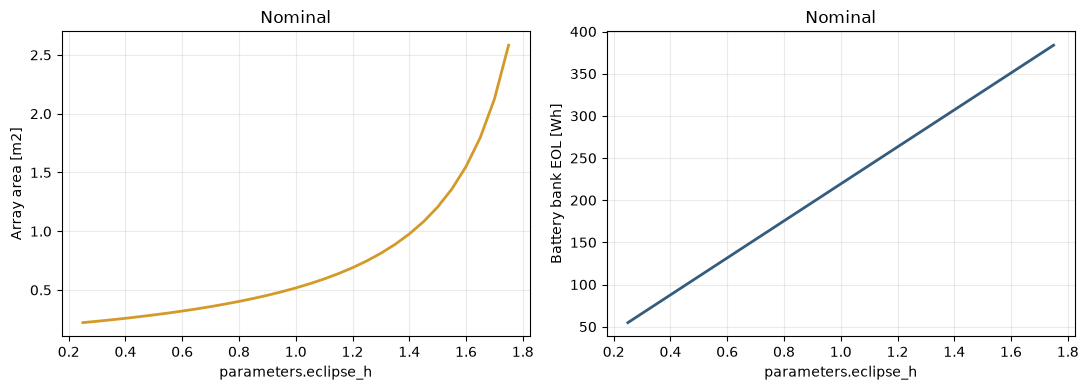

,Orbit average + margin [W],Peak + margin [W],Array power required at EOL [W],Array area [m2],Battery bank EOL [Wh],Battery bank BOL [Wh]
parameters.eclipse_h,,,,,,
0.25,42.152,119.236,63.743,0.222,54.829,NaN
0.50,44.590,119.236,82.541,0.288,109.657,NaN
0.75,47.027,119.236,108.859,0.380,164.486,NaN
1.00,49.465,119.236,148.335,0.517,219.315,NaN
1.25,51.902,119.236,214.130,0.747,274.144,NaN
1.50,54.340,119.236,345.719,1.206,328.972,NaN
1.75,56.777,119.236,740.485,2.583,383.801,NaN


In [17]:
def sweep(case, parameter, values, mode="nominal", linked_changes=None):
    records = []
    for value in values:
        changes = {parameter: float(value)}
        if linked_changes is not None:
            changes.update(linked_changes(float(value)))
        _, result = calculate(changed_case(case, changes), mode)
        records.append(result)
    frame = pd.DataFrame(records, index=np.asarray(values))
    frame.index.name = parameter
    return frame


sweep_parameter = "parameters.eclipse_h"
orbit_h = baseline["parameters"]["eclipse_h"] + baseline["parameters"]["sunlight_h"]
sweep_values = np.linspace(0.125 * orbit_h, 0.875 * orbit_h, 31)
sweep_mode = "nominal"

# Keep the current baseline orbit period fixed in this example.
# For any unrelated parameter, set linked_changes = None.
linked_changes = lambda eclipse_h: {"parameters.sunlight_h": orbit_h - eclipse_h}

sweep_results = sweep(baseline, sweep_parameter, sweep_values, sweep_mode, linked_changes)
if view["sweep_output"]:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric, color in zip(axes, ["Array area [m2]", "Battery bank EOL [Wh]"], ["#D49A29", "#355C7D"]):
        ax.plot(sweep_results.index, sweep_results[metric], color=color, linewidth=2)
        ax.set_xlabel(sweep_parameter)
        ax.set_ylabel(metric)
        ax.set_title(sweep_mode.capitalize())
    fig.tight_layout()
    plt.show()
    display(sweep_results[comparison_columns].iloc[::5].round(3))

## 6. Optional interactive comparison

Change one input and compare it with the baseline.

In [18]:
try:
    import ipywidgets as widgets
except ImportError:
    print("Optional: install ipywidgets for the interactive controls. Other sections work without it.")
else:
    paths = [f"parameters.{key}" for key in baseline["parameters"]]
    for group in ["loads", "safe_overrides"]:
        paths += [f"{group}.{key}.{field}" for key in baseline["loads"]
                  for field in ["active_W", "idle_W", "peak_W", "duty_e", "duty_d", "enabled"]]

    def get_input(path):
        parts = path.split(".")
        if parts[0] == "parameters":
            return baseline["parameters"][parts[1]]
        rows = baseline["loads"] if parts[0] == "loads" else mode_loads(baseline, "safe")
        return rows[parts[1]][parts[2]]

    parameter_widget = widgets.Dropdown(options=paths, value="parameters.eclipse_h",
                                       description="Input:", layout=widgets.Layout(width="650px"))
    value_widget = widgets.Text(value=str(get_input(parameter_widget.value)), description="Value:")
    mode_widget = widgets.Dropdown(options=["nominal", "safe"], description="Mode:")
    button = widgets.Button(description="Compare with baseline", layout=widgets.Layout(width="220px"))
    output_widget = widgets.Output()

    def select_input(change):
        value_widget.value = str(get_input(change["new"]))

    def compare_input(_):
        with output_widget:
            output_widget.clear_output(wait=True)
            try:
                text = value_widget.value.strip()
                old = get_input(parameter_widget.value)
                if isinstance(old, (bool, np.bool_)):
                    if text.lower() not in ["true", "false"]:
                        raise ValueError("Use True or False for enabled.")
                    value = text.lower() == "true"
                else:
                    value = None if text.lower() == "none" else float(text)
                variant = changed_case(baseline, {parameter_widget.value: value})
                before = calculate(baseline, mode_widget.value)[1]
                after = calculate(variant, mode_widget.value)[1]
                display(pd.DataFrame({"Baseline": before, "Variation": after,
                                      "Change": after-before}).round(3).fillna("TBD"))
            except (ValueError, TypeError, KeyError) as error:
                print(f"Check input: {error}")

    parameter_widget.observe(select_input, names="value")
    button.on_click(compare_input)
    display(widgets.VBox([parameter_widget, widgets.HBox([value_widget, mode_widget]), button, output_widget]))

## 7. Notes

Inputs and assumptions are documented in the report.